# Simulación de portafolio con Cholesky
María Fernanda Gómez Flores

Simulación de AAPL, MSFT y NVDA a un año con 10,000 escenarios.

In [123]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

### Precios y rendimientos
Descargamos los precios del 4 de noviembre de 2025 al 4 de noviembre de 2026 y sacamos los rendimientos logarítmicos diarios.

In [124]:
tickers = ["AAPL", "MSFT", "NVDA"]
prices = yf.download(tickers=tickers,period="1y")["Close"]
prices = prices[tickers].dropna()
rets = np.log(prices / prices.shift(1)).dropna()
rets

/var/folders/x9/60hcc2ln62d3r3xyv90d3wl40000gn/T/ipykernel_55091/1068622688.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers=tickers,period="1y")["Close"]
[*********************100%***********************]  3 of 3 completed


Ticker,AAPL,MSFT,NVDA
Date,,,
2025-11-11,0.021371,0.005283,-0.030037
2025-11-12,-0.006488,0.004824,0.003308
2025-11-13,-0.001903,-0.015477,-0.036467
2025-11-14,-0.001980,0.013597,0.017559
2025-11-17,-0.018338,-0.005287,-0.018951
...,...,...,...
2026-11-03,-0.019159,0.026983,0.022655
2026-11-04,0.051699,0.064678,-0.032253
2026-11-05,-0.015396,-0.036405,-0.097161


### Correlación
Calculamos la correlación entre los rendimientos de las tres acciones.

In [125]:
rets.corr()

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.000000,0.160278,0.043844
MSFT,0.160278,1.000000,0.231188
NVDA,0.043844,0.231188,1.000000


### Covarianza
Sacamos la matriz de covarianzas de los rendimientos diarios.

In [126]:
Sigma = rets.cov()
Sigma

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,0.000249,0.000053,0.000017
MSFT,0.000053,0.000447,0.000118
NVDA,0.000017,0.000118,0.000581


### Cholesky
Descomponemos la matriz de covarianzas para poder simular los rendimientos tomando en cuenta la relación entre las acciones.

In [127]:
L = np.linalg.cholesky(Sigma)
L

array([[0.01577947, 0.        , 0.        ],
       [0.00338707, 0.02085924, 0.        ],
       [0.00105688, 0.00547419, 0.02345151]])

### Rendimiento promedio
Calculamos el rendimiento promedio diario y lo pasamos a anual usando 252 días.

In [128]:
mu = rets.mean().values * 252
mu

array([ 0.26844293,  0.08343562, -0.10646762])

### Rendimientos y volatilidad anual
Revisamos los rendimientos promedio y la volatilidad que estamos usando para simular un año. Así podemos comparar los datos con los que utilizó el profe.

In [129]:
print("Rendimientos promedio anuales (%):")
print((rets.mean() * 252 * 100).round(2))

print("\nVolatilidades anuales (%):")
print((rets.std() * np.sqrt(252) * 100).round(2))

print("\nPeriodo utilizado:")
print(f"Del {prices.index.min().date()} al {prices.index.max().date()}")

Rendimientos promedio anuales (%):
Ticker
AAPL    26.84
MSFT     8.34
NVDA   -10.65
dtype: float64

Volatilidades anuales (%):
Ticker
AAPL    25.05
MSFT    33.55
NVDA    38.27
dtype: float64

Periodo utilizado:
Del 2025-11-10 al 2026-11-09


### Simulación
Generamos 10,000 números aleatorios normales para cada acción usando la semilla 67.

In [130]:
M = 10000
rng = np.random.default_rng(67)
epsilon = rng.standard_normal((len(tickers), M))
epsilon

array([[-0.57344526,  0.01921087, -0.11224464, ..., -0.1185902 ,
        -0.38123805,  0.64427913],
       [ 1.03523457,  0.53760986,  0.77641656, ..., -0.535036  ,
         0.12138792, -1.17492684],
       [ 0.19677523, -0.99251517, -0.22355122, ..., -0.13404009,
        -0.88868268,  0.38664158]])

### Rendimientos correlacionados
Multiplicamos los números aleatorios por la matriz de Cholesky para obtener los movimientos correlacionados.

In [131]:
Z = L @ epsilon
Z.T

array([[-0.00904866,  0.0196519 ,  0.00967569],
       [ 0.00030314,  0.0112792 , -0.02031269],
       [-0.00177116,  0.01581528, -0.00111099],
       ...,
       [-0.00187129, -0.01156212, -0.00619767],
       [-0.00601573,  0.00124078, -0.02057937],
       [ 0.01016638, -0.02232586,  0.00331647]])

### Precios futuros
Simulamos los precios de cada acción dentro de un año. Aquí ya estamos usando la volatilidad que viene de la matriz de covarianzas.

In [132]:
T = 1
n_dias = 252
S0 = prices.iloc[-1].values
mu = rets.mean().values * n_dias
vol = rets.std().values * np.sqrt(n_dias)

ST = S0 * np.exp(
    (mu - 0.5 * vol**2) * T
    + np.sqrt(n_dias * T) * Z.T
)
ST = pd.DataFrame(ST, columns=tickers)
ST.head()

,AAPL,MSFT,NVDA
0,385.033202,765.283863,174.069828
1,446.654239,670.037909,108.137735
2,432.186115,720.065567,146.675601
3,404.543870,794.379153,80.697462
4,636.860090,671.707885,89.731724


### Pesos del portafolio
Vamos a usar tres formas distintas de repartir los $100,000 entre AAPL, MSFT y NVDA. En el primero invertimos todo en AAPL, en el segundo repartimos casi igual y en el tercero le damos más peso a NVDA.

In [133]:
V0 = 100000

pesos = {
    "Escenario 1": np.array([1.00, 0.00, 0.00]),
    "Escenario 2": np.array([0.33, 0.33, 0.34]),
    "Escenario 3": np.array([0.20, 0.20, 0.60])
}

pd.DataFrame(pesos, index=tickers).T

,AAPL,MSFT,NVDA
Escenario 1,1.00,0.00,0.00
Escenario 2,0.33,0.33,0.34
Escenario 3,0.20,0.20,0.60


### Valor futuro de los tres portafolios
Con los mismos precios simulados calculamos cuántas acciones tendríamos en cada escenario y cuánto valdría el portafolio al final del año.

In [134]:
resultados = {}

for nombre, w in pesos.items():
    acciones = V0 * w / S0
    VT = ST.to_numpy() @ acciones
    PnL = VT - V0

    resultados[nombre] = {"VT": VT, "PnL": PnL}

pd.DataFrame({nombre: datos["VT"] for nombre, datos in resultados.items()}).head()

,Escenario 1,Escenario 2,Escenario 3
0,109793.036294,115679.302996,108488.342324
1,127364.406181,103166.028048,86367.544365
2,123238.789756,112166.333776,100319.271620
3,115356.544811,101508.121809,79312.601747
4,181602.009140,117662.950349,91095.320414


### Gráfica del valor futuro
Comparamos cómo se distribuye el valor de los tres portafolios antes de restarle el capital inicial. La línea marca los $100,000 que invertimos.

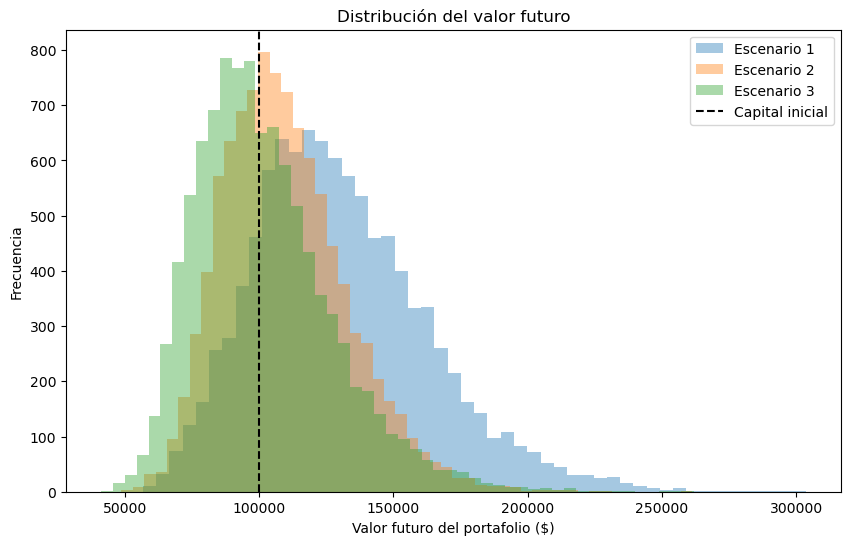

In [135]:
plt.figure(figsize=(10, 6))

for nombre, datos in resultados.items():
    plt.hist(datos["VT"], bins=50, alpha=0.4, label=nombre)

plt.axvline(V0, color="black", linestyle="--", label="Capital inicial")
plt.title("Distribución del valor futuro")
plt.xlabel("Valor futuro del portafolio ($)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

### Ganancias y pérdidas
Ahora a cada valor futuro le restamos los $100,000 iniciales.

$$P\&L = V_T - V_0$$

Los valores negativos son pérdidas y los positivos son ganancias.

In [136]:
pd.DataFrame({nombre: datos["PnL"] for nombre, datos in resultados.items()}).head()

,Escenario 1,Escenario 2,Escenario 3
0,9793.036294,15679.302996,8488.342324
1,27364.406181,3166.028048,-13632.455635
2,23238.789756,12166.333776,319.271620
3,15356.544811,1508.121809,-20687.398253
4,81602.009140,17662.950349,-8904.679586


### Gráfica de ganancias y pérdidas
Graficamos los tres escenarios después de restar el capital inicial. El cero significa que recuperamos exactamente lo que invertimos.

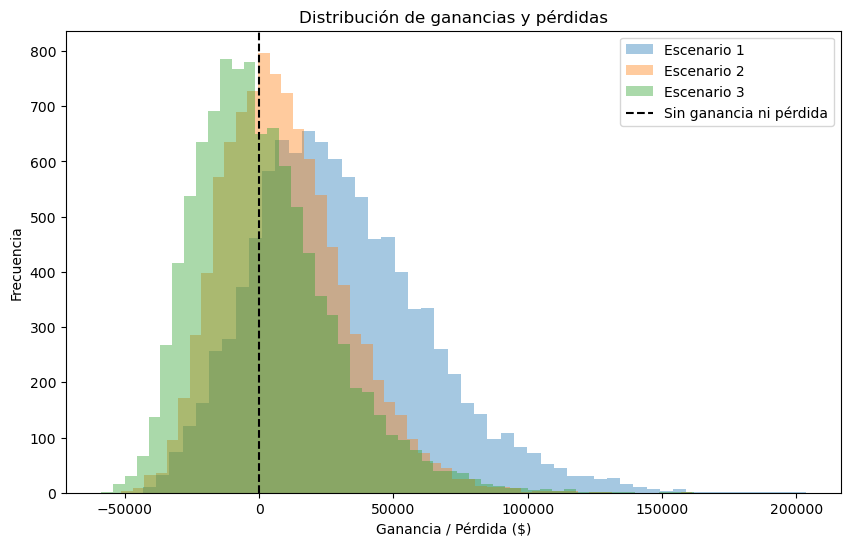

In [137]:
plt.figure(figsize=(10, 6))

for nombre, datos in resultados.items():
    plt.hist(datos["PnL"], bins=50, alpha=0.4, label=nombre)

plt.axvline(0, color="black", linestyle="--", label="Sin ganancia ni pérdida")
plt.title("Distribución de ganancias y pérdidas")
plt.xlabel("Ganancia / Pérdida ($)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

### Promedio del valor final
Sacamos el promedio de los 10,000 valores finales de cada portafolio para comparar los tres escenarios. También calculamos cuánto se gana o pierde en promedio después de restar los $100,000 iniciales.

In [138]:
for nombre, datos in resultados.items():
    print(nombre)
    print(f"Valor final promedio: ${datos['VT'].mean():,.2f}")
    print(f"Ganancia promedio: ${datos['PnL'].mean():,.2f}")
    print()

Escenario 1
Valor final promedio: $130,634.15
Ganancia promedio: $30,634.15

Escenario 2
Valor final promedio: $109,546.25
Ganancia promedio: $9,546.25

Escenario 3
Valor final promedio: $101,725.78
Ganancia promedio: $1,725.78



### Comparación de escenarios
Calculamos la ganancia promedio, la volatilidad del rendimiento simulado y la probabilidad de terminar con pérdidas para comparar qué tanto cambia el resultado con los pesos.

In [139]:
resumen = []

for nombre, datos in resultados.items():
    pnl = datos["PnL"]
    resumen.append({
        "Escenario": nombre,
        "Valor futuro promedio ($)": datos["VT"].mean(),
        "Ganancia promedio ($)": pnl.mean(),
        "Volatilidad del rendimiento (%)": np.std(pnl / V0, ddof=1) * 100,
        "Probabilidad de pérdida (%)": np.mean(pnl < 0) * 100
    })

comparacion = pd.DataFrame(resumen).set_index("Escenario")
comparacion.round(2)

,Valor futuro promedio ($),Ganancia promedio ($),Volatilidad del rendimiento (%),Probabilidad de pérdida (%)
Escenario,,,,
Escenario 1,130634.15,30634.15,32.80,16.54
Escenario 2,109546.25,9546.25,23.07,37.03
Escenario 3,101725.78,1725.78,25.58,53.51


### VaR y CVaR
Calculamos el VaR y el CVaR al 95% de confianza para cada portafolio con las ganancias y pérdidas simuladas. El VaR marca el 5% de los peores resultados y el CVaR es el promedio de esos resultados. Los calculamos como pérdidas respecto a los $100,000 iniciales.

In [ ]:
riesgos = []

for nombre, datos in resultados.items():
    pnl = np.asarray(datos["PnL"])
    limite_5 = np.percentile(pnl, 5)
    cola = pnl[pnl <= limite_5]

    riesgos.append({
        "Escenario": nombre,
        "VaR 95% ($)": -limite_5,
        "CVaR 95% ($)": -cola.mean(),
        "Probabilidad de pérdida (%)": (pnl < 0).mean() * 100
    })

tabla_riesgos = pd.DataFrame(riesgos).set_index("Escenario")
tabla_riesgos.round(2)

### Gráficas de VaR y CVaR
Graficamos las ganancias y pérdidas de cada escenario por separado. La parte sombreada es el 5% de los resultados más bajos. La línea del VaR marca el límite de esa cola y la del CVaR marca su promedio. Las líneas se muestran en la escala de ganancias y pérdidas.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (nombre, datos) in zip(axes, resultados.items()):
    pnl = np.asarray(datos["PnL"])
    limite_5 = np.percentile(pnl, 5)
    cvar_pnl = pnl[pnl <= limite_5].mean()

    ax.hist(pnl, bins=50, edgecolor="black", alpha=0.65)
    ax.hist(pnl[pnl <= limite_5], bins=30, color="tomato", alpha=0.75,
            label="5% de peores resultados")
    ax.axvline(limite_5, color="red", linestyle="--",
               label=f"VaR: ${-limite_5:,.0f}")
    ax.axvline(cvar_pnl, color="darkorange", linestyle=":",
               label=f"CVaR: ${-cvar_pnl:,.0f}")
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(nombre)
    ax.set_xlabel("Ganancia / Pérdida ($)")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Frecuencia")
fig.suptitle("VaR y CVaR al 95% de confianza")
plt.tight_layout()
plt.show()